# Lab 5. How language models see your language

Token counts for Articles 1–30 of the Universal Declaration of Human Rights in 22 languages, with three of OpenAI's published tokenisers. The counts in `data/udhr_tokens.csv` come from `scripts/compute_tokens.mjs` (js-tiktoken, as in the browser) and are re-checked with Python's tiktoken in `tests/check_tokens.py`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TEAL, OCHRE, INK = "#008f86", "#b07d12", "#1c2b3a"
df = pd.read_csv("../data/udhr_tokens.csv")
df[["language", "script", "tokens_r50k_base", "tokens_cl100k_base", "tokens_o200k_base",
    "premium_r50k_base", "premium_cl100k_base", "premium_o200k_base"]].sort_values("premium_o200k_base", ascending=False)

,language,script,tokens_r50k_base,tokens_cl100k_base,tokens_o200k_base,premium_r50k_base,premium_cl100k_base,premium_o200k_base
21,Amharic,Ethiopic,16118,15959,10772,9.70,9.70,6.55
19,Yoruba,Latin (with diacritics),9076,7767,6716,5.46,4.72,4.08
7,Burmese,Myanmar,34893,24538,6645,21.01,14.92,4.04
6,Khmer,Khmer,24623,13902,5271,14.82,8.45,3.21
12,Tamil,Tamil,30415,15320,4029,18.31,9.31,2.45
5,Thai,Thai,14641,7207,3159,8.81,4.38,1.92
3,Japanese,Kanji and kana,5506,4024,2993,3.31,2.45,1.82
9,Tagalog,Latin,4027,3546,2798,2.42,2.16,1.70
11,Bengali,Bengali,15934,9664,2755,9.59,5.88,1.68
20,Zulu,Latin,3657,3334,2646,2.20,2.03,1.61


## Token premium across three generations of tokeniser

Premium = tokens for the language ÷ tokens for English. 1.0 means parity with English.

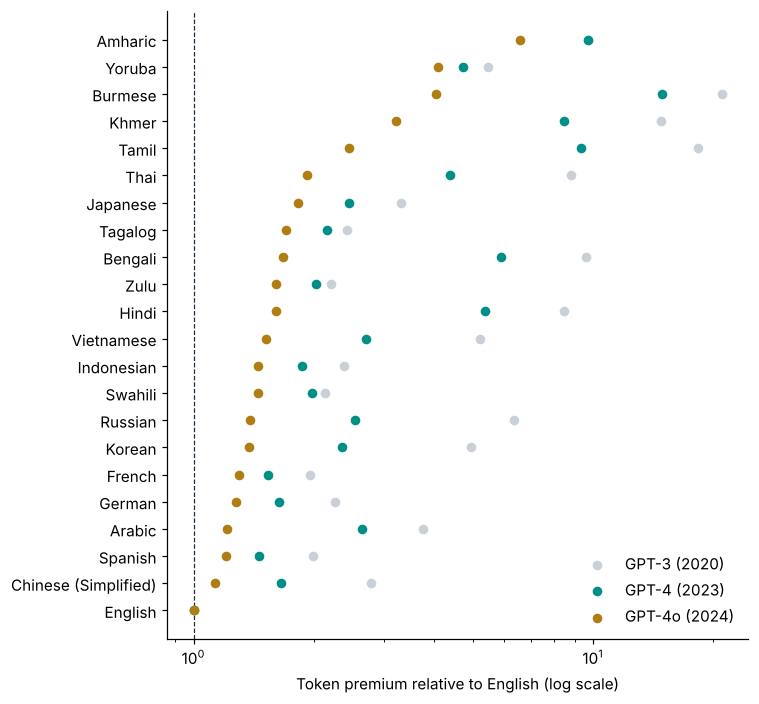

In [2]:
order = df.sort_values("premium_o200k_base")
fig, ax = plt.subplots(figsize=(7, 6.5))
for col, label, c in [("premium_r50k_base", "GPT-3 (2020)", "#c9d0d8"), ("premium_cl100k_base", "GPT-4 (2023)", TEAL), ("premium_o200k_base", "GPT-4o (2024)", OCHRE)]:
    ax.scatter(order[col], order["language"], label=label, color=c, s=28, zorder=3)
ax.axvline(1, color=INK, lw=0.8, ls="--")
ax.set_xscale("log"); ax.set_xlabel("Token premium relative to English (log scale)")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout()

## Did newer tokenisers close the gap?

The ratio below shows how many times smaller each language's premium became from GPT-3 to GPT-4o.

In [3]:
df["improvement"] = df["premium_r50k_base"] / df["premium_o200k_base"]
df[["language", "premium_r50k_base", "premium_o200k_base", "improvement"]].sort_values("improvement", ascending=False).head(8)

,language,premium_r50k_base,premium_o200k_base,improvement
12,Tamil,18.31,2.45,7.47
11,Bengali,9.59,1.68,5.72
10,Hindi,8.46,1.61,5.26
7,Burmese,21.01,4.04,5.20
6,Khmer,14.82,3.21,4.62
5,Thai,8.81,1.92,4.59
14,Russian,6.33,1.39,4.57
4,Korean,4.95,1.38,3.59


## Is the premium just about bytes?

Tokenisers work on UTF-8 bytes. Scripts such as Thai, Khmer and Burmese use three bytes per character, Latin-script English one. The correlation below checks how far bytes per character track the premium with each tokeniser.

In [4]:
df["bytes_per_char"] = df["bytes"] / df["characters"]
for col in ["premium_r50k_base", "premium_cl100k_base", "premium_o200k_base"]:
    r = df["bytes_per_char"].corr(df[col], method="spearman")
    print(f"{col:22s} Spearman rho with bytes per character = {r:.2f}")

premium_r50k_base      Spearman rho with bytes per character = 0.74
premium_cl100k_base    Spearman rho with bytes per character = 0.66
premium_o200k_base     Spearman rho with bytes per character = 0.47


## Count it yourself

With internet access, `tiktoken` downloads the vocabulary on first use. If `scripts/compute_tokens.mjs` has been run, the local copy in `data/ranks/` is used instead.

In [5]:
import base64, tiktoken
import tiktoken_ext.openai_public as public

def encoding(name):
    local = Path("../data/ranks") / f"{name}.tiktoken"
    if not local.exists():
        return tiktoken.get_encoding(name)
    def from_local(_url, expected_hash=None):
        return {base64.b64decode(t): int(r) for t, r in (l.split(" ") for l in local.read_text().splitlines())}
    original, public.load_tiktoken_bpe = public.load_tiktoken_bpe, from_local
    try:
        return tiktoken.Encoding(**getattr(public, name)())
    finally:
        public.load_tiktoken_bpe = original

enc = encoding("o200k_base")
sentence = Path("../data/src/udhr/vi.txt").read_text(encoding="utf-8").splitlines()[1]
ids = enc.encode(sentence)
print(len(ids), "tokens for Article 1 in Vietnamese")
print([enc.decode([i]) for i in ids][:20])

50 tokens for Article 1 in Vietnamese
['T', 'ất', ' cả', ' mọi', ' người', ' sinh', ' ra', ' đều', ' được', ' tự', ' do', ' và', ' bình', ' đ', 'ẳng', ' về', ' nhân', ' phẩm', ' và', ' quyền']
